<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%203/Latihan_Praktikum_3_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3 — Preprocessing, Imbalanced Data, dan Evaluasi Model



In [1]:
# Jika diperlukan di Google Colab, jalankan instalasi ini.
!pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


## Praktikum 3.2 — Import dataset dan membuat missing values

In [2]:
# Membuat dataset sintetis dengan kelas tidak seimbang
X, y = make_classification(
    n_samples=2000,
    n_features=8,
    weights=[0.95, 0.05],
    random_state=42
)

df = pd.DataFrame(X, columns=[f"fitur_{i}" for i in range(8)])
df["target"] = y

# Simulasikan missing values hanya pada kolom fitur (bukan target)
rng = np.random.RandomState(42)
mask = rng.rand(len(df), 8) < 0.05
df_missing = df.copy()
df_missing.loc[:, [f"fitur_{i}" for i in range(8)]] = (
    df_missing[[f"fitur_{i}" for i in range(8)]].mask(mask)
)

print("Ukuran dataset:", df_missing.shape)
print("\nJumlah missing values per kolom:")
display(df_missing.isnull().sum().to_frame("jumlah_missing"))
print("\nDistribusi target:")
display(df_missing["target"].value_counts().sort_index().rename(index={0:"Kelas 0", 1:"Kelas 1"}).to_frame("jumlah"))

Ukuran dataset: (2000, 9)

Jumlah missing values per kolom:


,jumlah_missing
fitur_0,99
fitur_1,106
fitur_2,110
fitur_3,104
fitur_4,85
fitur_5,102
fitur_6,95
fitur_7,105
target,0



Distribusi target:


,jumlah
target,
Kelas 0,1888
Kelas 1,112


**Catatan perbaikan dari potongan modul:** apabila `mask` dibuat menggunakan `rng.rand(*df.shape)`, kolom `target` ikut terkena missing value. Pada notebook ini mask dibuat untuk 8 kolom fitur saja agar label tetap utuh dan model dapat dilatih.

## Praktikum 3.3 — Preprocessing

In [3]:
fitur_cols = [c for c in df_missing.columns if c.startswith("fitur")]

# Imputasi KNN hanya pada kolom fitur
imputer = KNNImputer(n_neighbors=5)
df_imputed = df_missing.copy()
df_imputed[fitur_cols] = imputer.fit_transform(df_missing[fitur_cols])

# Deteksi outlier dengan Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=42)
df_imputed["is_outlier"] = iso.fit_predict(df_imputed[fitur_cols])

jumlah_outlier = (df_imputed["is_outlier"] == -1).sum()
print("Jumlah outlier terdeteksi:", jumlah_outlier)
print("Selesai imputasi. Sisa missing pada fitur:", int(df_imputed[fitur_cols].isnull().sum().sum()))

display(df_imputed.head())

Jumlah outlier terdeteksi: 40
Selesai imputasi. Sisa missing pada fitur: 0


,fitur_0,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,target,is_outlier
0,-1.279094,0.068207,0.817992,0.936149,0.413754,0.242450,-0.442947,0.632907,0,1
1,-2.341799,-0.889845,0.417344,2.730166,0.867805,0.227405,0.147277,0.293524,0,1
2,2.250661,0.391209,0.581782,-1.850790,-1.579436,-0.817892,0.587450,-0.940332,0,1
3,1.707605,-1.325157,2.105087,0.319733,-1.613368,0.323095,2.071255,-2.181197,0,1
4,-0.451943,-0.035420,-0.527066,0.558951,-0.800293,-0.017928,0.058650,0.029354,0,1


**Keterangan:** Isolation Forest memberi label `-1` untuk outlier dan `1` untuk data normal. Sesuai alur praktikum, hasil deteksi disimpan pada kolom `is_outlier`; baris outlier tidak langsung dihapus.

## Praktikum 3.4 — Training model dengan dan tanpa SMOTE

In [4]:
X = df_imputed[fitur_cols]
y = df_imputed["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Baseline: tanpa penanganan imbalance
model_base = LogisticRegression(max_iter=1000)
model_base.fit(X_train, y_train)

# SMOTE hanya diterapkan pada data training
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

model_smote = LogisticRegression(max_iter=1000)
model_smote.fit(X_train_sm, y_train_sm)

# Alternatif: class_weight balanced
model_cw = LogisticRegression(max_iter=1000, class_weight="balanced")
model_cw.fit(X_train, y_train)

print("Distribusi y_train sebelum SMOTE:")
display(y_train.value_counts().sort_index().to_frame("jumlah"))
print("Distribusi y_train setelah SMOTE:")
display(y_train_sm.value_counts().sort_index().to_frame("jumlah"))

Distribusi y_train sebelum SMOTE:


,jumlah
target,
0,1510
1,90


Distribusi y_train setelah SMOTE:


,jumlah
target,
0,1510
1,1510


## Praktikum 3.5 — Evaluasi model

In [5]:
def evaluasi_model(nama, model, X_test, y_test):
    y_pred = model.predict(X_test)
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    }

hasil_awal = [
    evaluasi_model("Baseline (tanpa SMOTE)", model_base, X_test, y_test),
    evaluasi_model("Dengan SMOTE", model_smote, X_test, y_test),
    evaluasi_model("Class Weight", model_cw, X_test, y_test)
]
tabel_awal = pd.DataFrame(hasil_awal).set_index("Model")
display(tabel_awal.round(3))

print("Classification report — model SMOTE:")
print(classification_report(y_test, model_smote.predict(X_test), zero_division=0))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline (tanpa SMOTE),0.955,0.643,0.409,0.500
Dengan SMOTE,0.888,0.298,0.773,0.430
Class Weight,0.870,0.266,0.773,0.395


Classification report — model SMOTE:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94       378
           1       0.30      0.77      0.43        22

    accuracy                           0.89       400
   macro avg       0.64      0.83      0.68       400
weighted avg       0.95      0.89      0.91       400



## Praktikum 3.6 — Visualisasi distribusi kelas

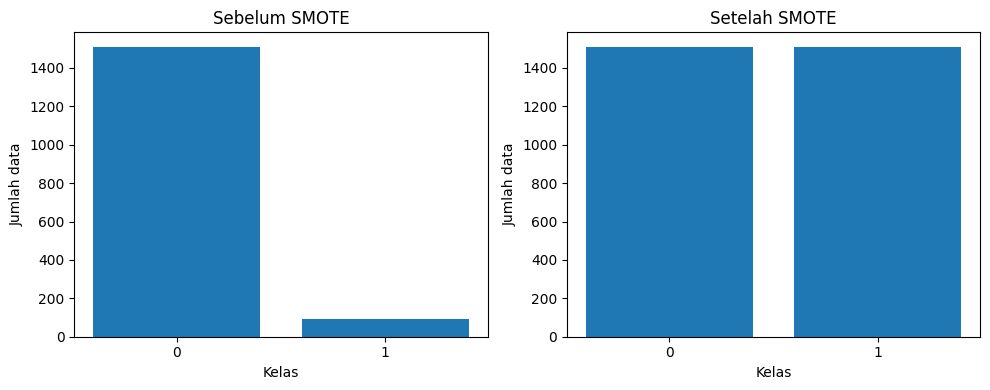

In [6]:
before = y_train.value_counts().sort_index()
after = y_train_sm.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(before.index.astype(str), before.values)
axes[0].set_title("Sebelum SMOTE")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah data")

axes[1].bar(after.index.astype(str), after.values)
axes[1].set_title("Setelah SMOTE")
axes[1].set_xlabel("Kelas")
axes[1].set_ylabel("Jumlah data")

plt.tight_layout()
plt.show()

## Praktikum 3.7 — Undersampling dengan RandomUnderSampler

In [7]:
rus = RandomUnderSampler(random_state=42)
X_train_r, y_train_r = rus.fit_resample(X_train, y_train)

model_rus = LogisticRegression(max_iter=1000)
model_rus.fit(X_train_r, y_train_r)

print("Distribusi y_train setelah RandomUnderSampler:")
display(y_train_r.value_counts().sort_index().to_frame("jumlah"))

# Bandingkan semua pendekatan pada test set yang sama
hasil_semua = [
    evaluasi_model("Baseline", model_base, X_test, y_test),
    evaluasi_model("SMOTE", model_smote, X_test, y_test),
    evaluasi_model("Class Weight", model_cw, X_test, y_test),
    evaluasi_model("Undersampling", model_rus, X_test, y_test)
]
tabel_semua = pd.DataFrame(hasil_semua).set_index("Model")
display(tabel_semua.round(3))

Distribusi y_train setelah RandomUnderSampler:


,jumlah
target,
0,90
1,90


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline,0.955,0.643,0.409,0.500
SMOTE,0.888,0.298,0.773,0.430
Class Weight,0.870,0.266,0.773,0.395
Undersampling,0.890,0.310,0.818,0.450


## Latihan Praktikum 1 — Perbandingan strategi imputasi Mean dan KNN

Strategi imputasi dibandingkan menggunakan dataset dan pembagian train-test yang sama. Imputer di-*fit* pada data training, kemudian diterapkan ke data test agar informasi data test tidak bocor ke proses training.

In [8]:
# Split data mentah yang masih memiliki missing values
X_raw = df_missing[fitur_cols]
y_raw = df_missing["target"]

Xtr_raw, Xte_raw, ytr, yte = train_test_split(
    X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=42
)

# A. Mean Imputation
mean_imputer = SimpleImputer(strategy="mean")
Xtr_mean = mean_imputer.fit_transform(Xtr_raw)
Xte_mean = mean_imputer.transform(Xte_raw)

model_mean = LogisticRegression(max_iter=1000)
model_mean.fit(Xtr_mean, ytr)
pred_mean = model_mean.predict(Xte_mean)

# B. KNN Imputation
knn_imputer = KNNImputer(n_neighbors=5)
Xtr_knn = knn_imputer.fit_transform(Xtr_raw)
Xte_knn = knn_imputer.transform(Xte_raw)

model_knn = LogisticRegression(max_iter=1000)
model_knn.fit(Xtr_knn, ytr)
pred_knn = model_knn.predict(Xte_knn)

hasil_imputasi = pd.DataFrame([
    {
        "Strategi": "Mean Imputation",
        "Accuracy": accuracy_score(yte, pred_mean),
        "Precision": precision_score(yte, pred_mean, zero_division=0),
        "Recall": recall_score(yte, pred_mean, zero_division=0),
        "F1-Score": f1_score(yte, pred_mean, zero_division=0)
    },
    {
        "Strategi": "KNN Imputer",
        "Accuracy": accuracy_score(yte, pred_knn),
        "Precision": precision_score(yte, pred_knn, zero_division=0),
        "Recall": recall_score(yte, pred_knn, zero_division=0),
        "F1-Score": f1_score(yte, pred_knn, zero_division=0)
    }
]).set_index("Strategi")

display(hasil_imputasi.round(3))
print("Strategi dengan F1-Score tertinggi:", hasil_imputasi["F1-Score"].idxmax())

,Accuracy,Precision,Recall,F1-Score
Strategi,,,,
Mean Imputation,0.950,0.571,0.364,0.444
KNN Imputer,0.952,0.600,0.409,0.486


Strategi dengan F1-Score tertinggi: KNN Imputer


## Latihan Praktikum 2 — Efektivitas penanganan imbalanced data

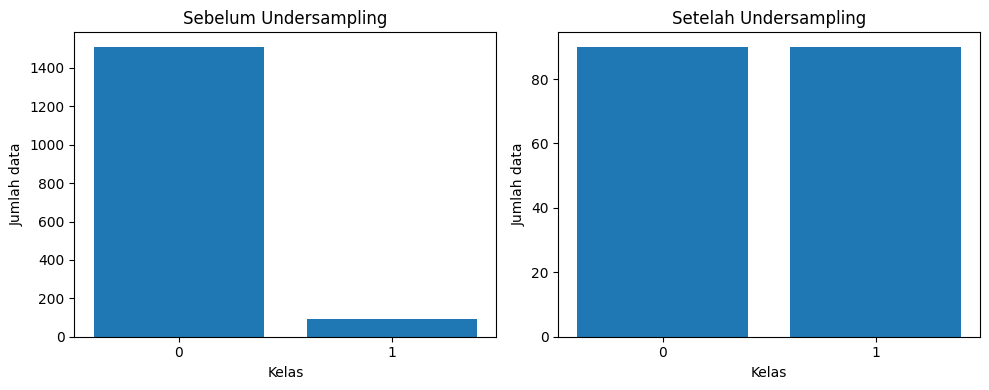

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline,0.955,0.643,0.409,0.500
Undersampling,0.890,0.310,0.818,0.450
SMOTE,0.888,0.298,0.773,0.430
Class Weight,0.870,0.266,0.773,0.395


Pendekatan dengan F1-Score tertinggi: Baseline
Pendekatan dengan Recall tertinggi: Undersampling


In [10]:
# Visualisasi distribusi kelas: sebelum dan sesudah undersampling
before_rus = y_train.value_counts().sort_index()
after_rus = y_train_r.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(before_rus.index.astype(str), before_rus.values)
axes[0].set_title("Sebelum Undersampling")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah data")

axes[1].bar(after_rus.index.astype(str), after_rus.values)
axes[1].set_title("Setelah Undersampling")
axes[1].set_xlabel("Kelas")
axes[1].set_ylabel("Jumlah data")

plt.tight_layout()
plt.show()

# Ringkasan F1-Score dan Recall dari semua pendekatan
ringkasan = tabel_semua[["Accuracy", "Precision", "Recall", "F1-Score"]].sort_values(
    by="F1-Score", ascending=False
)
display(ringkasan.round(3))

print("Pendekatan dengan F1-Score tertinggi:",
      ringkasan["F1-Score"].idxmax())
print("Pendekatan dengan Recall tertinggi:",
      ringkasan["Recall"].idxmax())

## Kesimpulan dan interpretasi

1. **Accuracy tidak cukup untuk data tidak seimbang.** Model dapat memperoleh akurasi tinggi dengan lebih sering menebak kelas mayoritas, tetapi gagal mengenali kelas minoritas.
2. **F1-Score** menggabungkan Precision dan Recall sehingga lebih informatif ketika kedua aspek penting. Jika tujuan utama adalah menangkap sebanyak mungkin kasus kelas minoritas, perhatikan Recall juga.
3. **SMOTE** menambah sampel sintetis kelas minoritas pada data training. **Undersampling** mengurangi sampel kelas mayoritas sehingga informasi data dapat berkurang. **Class Weight** memberi penalti lebih besar pada kesalahan kelas minoritas tanpa mengubah jumlah data.
4. Tidak ada pendekatan yang selalu paling baik. Gunakan tabel hasil yang muncul setelah notebook dijalankan untuk menentukan metode terbaik pada dataset ini.
5. Pada eksperimen ini, imputasi dan deteksi outlier di bagian Praktikum 3.3 mengikuti alur modul (sebelum split). Untuk eksperimen yang lebih ketat, preprocessing sebaiknya di-*fit* hanya pada data training, seperti yang sudah diterapkan pada latihan imputasi Mean vs KNN.

**Catatan pelaporan:** tuliskan angka F1-Score dari output Google Colab, bukan menyalin angka contoh dari sumber lain, karena hasil dapat bergantung pada versi library dan perubahan kode.